# Where the final net goes wrong

The final net scored 99.34% on the MNIST testing set, so it got 66 of the 10,000 images wrong. This notebook sets out the structure of the net, then finds those 66 images and shows them.

- **No training happens here.** It loads the saved net, so these are exactly the mistakes behind the reported score.
- **This is for the report only.** Changing the net because of what appears here would use the testing set to pick a design, and the test score would no longer be fair.

**You don't need to run this, because every output is saved below.** To run it yourself in Colab:

1. Choose File > Upload notebook, and pick this file.
2. Click the folder icon on the left, and upload `code/kerasMNIST_CNN.keras` from this repo.
3. Choose Runtime > Run all. It takes under a minute, and it doesn't need a GPU.

## Load the net and the testing set

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model
from tensorflow.keras.datasets import mnist

BLUE, ORANGE = '#2a78d6', '#eb6834'
plt.rcParams['figure.dpi'] = 150


# The saved net.  A new Colab session starts with no files, so upload it first.

for path in ['kerasMNIST_CNN.keras', 'code/kerasMNIST_CNN.keras']:
    if os.path.exists(path):
        model = load_model(path)
        break
else:
    raise FileNotFoundError("Upload kerasMNIST_CNN.keras with the Files panel, then run this cell again.")

_, (testing_inputs, testing_labels) = mnist.load_data()

testing_images = (testing_inputs.astype('float32')/255)[:,:,:,np.newaxis]

## The structure of the net

The net has **22 layers**, not counting the input. Six of them are the main learning layers: 5 convolutional and 1 Dense.

| Layer type | How many | What it does |
|---|---:|---|
| Conv2D | 5 | Slides 3 × 3 filters across the image to detect features |
| BatchNormalization | 5 | Rescales the outputs of each convolutional layer |
| Activation | 6 | 5 ReLU after the convolutional layers, and softmax at the end |
| MaxPooling2D | 2 | Halves the height and width of the image |
| Dropout | 2 | Turns off 10% of the outputs on each training step, and is off during testing |
| GlobalAveragePooling2D | 1 | Averages each of the 48 final slices down to one number |
| Dense | 1 | Turns those 48 numbers into the 10 digit outputs |

The net takes a 28 × 28 image, and its slices grow from 12 to 24 to 48 as the image shrinks to 7 × 7. The cell below reads each layer from the saved net, so it shows exactly what was trained.

In [2]:
from collections import Counter


# Describe one layer, using the settings stored in the saved net.

def describe(layer):
    kind = type(layer).__name__
    if kind == 'Conv2D':
        return "Conv2D, {} slices, {} x {}".format(layer.filters, *layer.kernel_size)
    if kind == 'MaxPooling2D':
        return "MaxPooling2D, {} x {}".format(*layer.pool_size)
    if kind == 'Dropout':
        return "Dropout, {}".format(layer.rate)
    if kind == 'Dense':
        return "Dense, {} outputs".format(layer.units)
    if kind == 'Activation':
        return "Activation, {}".format(layer.activation.__name__)
    return kind


print("{:>3}  {:<28}{:<16}{:>8}".format('', 'Layer', 'Output shape', 'Weights'))

for number, layer in enumerate(model.layers, 1):
    shape = " x ".join(str(size) for size in layer.output.shape[1:])
    print("{:>3}  {:<28}{:<16}{:>8,}".format(number, describe(layer), shape, layer.count_params()))

print("{:>3}  {:<28}{:<16}{:>8,}".format('', 'Total', '', model.count_params()))

print()
print("Layers by type:")
for kind, count in Counter(type(layer).__name__ for layer in model.layers).items():
    print("  {:<24}{:>3}".format(kind, count))
print("  {:<24}{:>3}".format('Total', len(model.layers)))

     Layer                       Output shape     Weights
  1  Conv2D, 12 slices, 3 x 3    28 x 28 x 12         120
  2  BatchNormalization          28 x 28 x 12          48
  3  Activation, relu            28 x 28 x 12           0
  4  Conv2D, 12 slices, 3 x 3    28 x 28 x 12       1,308
  5  BatchNormalization          28 x 28 x 12          48
  6  Activation, relu            28 x 28 x 12           0
  7  MaxPooling2D, 2 x 2         14 x 14 x 12           0
  8  Dropout, 0.1                14 x 14 x 12           0
  9  Conv2D, 24 slices, 3 x 3    14 x 14 x 24       2,616
 10  BatchNormalization          14 x 14 x 24          96
 11  Activation, relu            14 x 14 x 24           0
 12  Conv2D, 24 slices, 3 x 3    14 x 14 x 24       5,208
 13  BatchNormalization          14 x 14 x 24          96
 14  Activation, relu            14 x 14 x 24           0
 15  MaxPooling2D, 2 x 2         7 x 7 x 24             0
 16  Dropout, 0.1                7 x 7 x 24             0
 17  Conv2D, 4

## Find the mistakes

The predicted label is the index of the largest of the ten outputs. That largest output is used here as the net's confidence, from 0 to 1. The first line below should say 9934, or this isn't the right net.

In [3]:
# The responses are a 10000 x 10 matrix, one row of ten outputs per image.

responses = model.predict(testing_images, verbose=0)
predicted_labels = np.argmax(responses, axis=1)
confidence = np.max(responses, axis=1)

wrong = np.flatnonzero(predicted_labels != testing_labels)

print("Correct: {} of {}".format(len(testing_labels)-len(wrong), len(testing_labels)))
print("Wrong:   {}".format(len(wrong)))

Correct: 9934 of 10000
Wrong:   66


In [4]:
# Show a set of test images in a grid.  Each label gives the true digit, the
# predicted digit and the confidence, so "9→4 87%" is a 9 read as a 4 at 87%.

def show(indices, columns=11, save_as=None):
    rows = int(np.ceil(len(indices)/columns))
    fig, axes = plt.subplots(rows, columns, figsize=(columns*0.62, rows*0.86), squeeze=False)

    for ax in axes.flat:
        ax.axis('off')

    for ax, index in zip(axes.flat, indices):
        ax.imshow(testing_inputs[index], cmap='gray_r', vmin=0, vmax=255)
        ax.set_title("{}→{} {:.0f}%".format(testing_labels[index], predicted_labels[index], confidence[index]*100),
                     fontsize=7, pad=3)

    fig.tight_layout(pad=0.3, w_pad=0.2, h_pad=0.5)
    if save_as:
        fig.savefig(save_as, dpi=220, facecolor='white')
    plt.show()

## All 66 mistakes

These are sorted by true digit, then by predicted digit. A label of `9→4 87%` means a true 9, read as a 4, at 87% confidence. The grid is also saved as `figures/3.3_errors.png`.

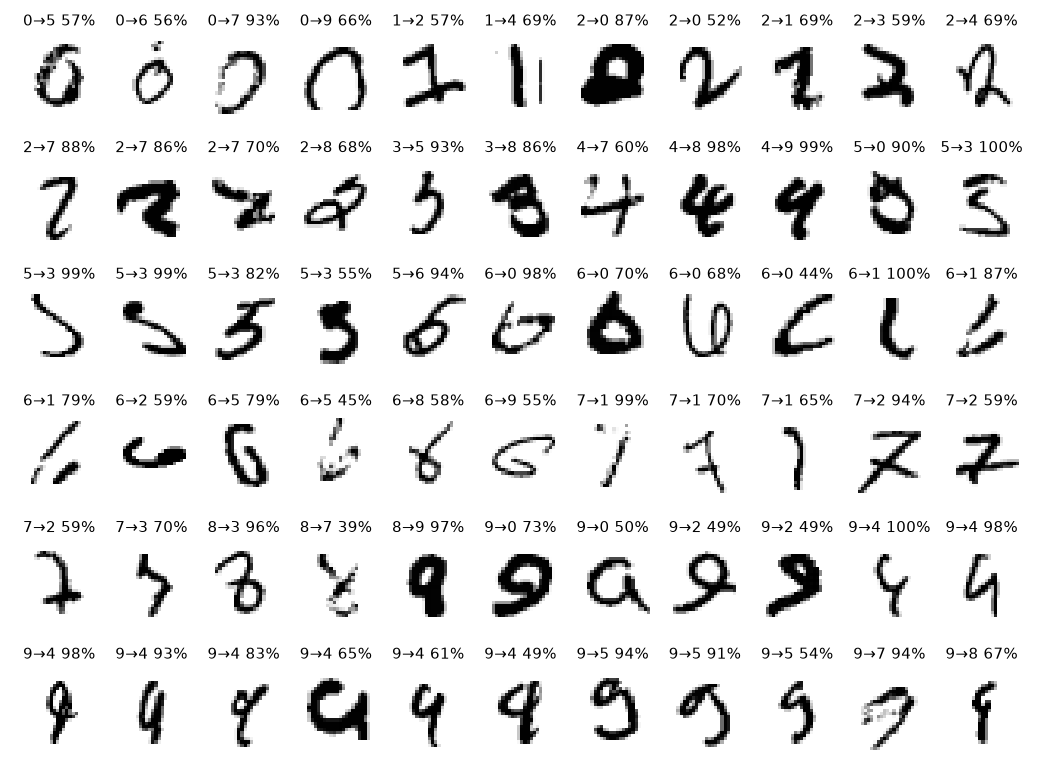

In [5]:
order = np.lexsort((-confidence[wrong], predicted_labels[wrong], testing_labels[wrong]))

os.makedirs('figures', exist_ok=True)

show(wrong[order], save_as='figures/3.3_errors.png')

## The most common errors

The confusion matrix showed these three errors most often. Here are the actual images.

True 9 read as 4: 8 times


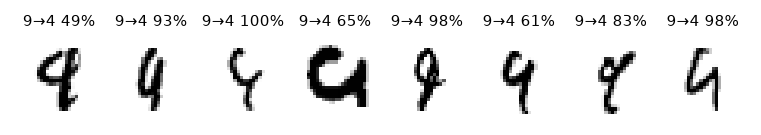

True 5 read as 3: 5 times


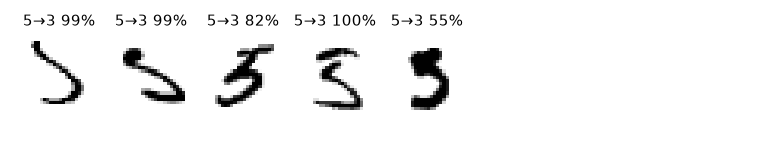

True 6 read as 0: 4 times


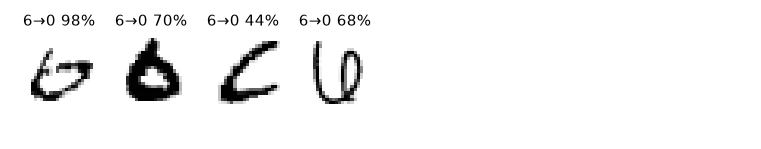

In [6]:
for true, predicted in [(9, 4), (5, 3), (6, 0)]:
    pair = wrong[(testing_labels[wrong] == true) & (predicted_labels[wrong] == predicted)]
    print("True {} read as {}: {} times".format(true, predicted, len(pair)))
    show(pair, columns=8)

## How sure was the net when it was wrong?

A net that is unsure when it fails is more useful than one that fails with full confidence. The chart counts the 66 mistakes by confidence.

Median confidence on correct images:  100.0%


Median confidence on the mistakes:    70.2%
Mistakes below 60% confidence:        19 of 66
Mistakes at 90% confidence or above:  22 of 66
Correct images below 60% confidence:  10 of 9934
Right digit was the second choice:    58 of 66


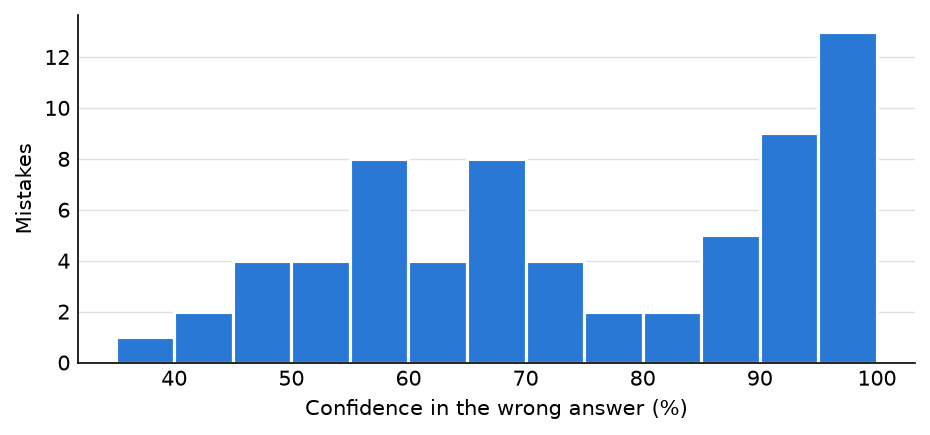

In [7]:
right = np.flatnonzero(predicted_labels == testing_labels)

second_choice = np.argsort(responses, axis=1)[:,-2]
close = np.sum(second_choice[wrong] == testing_labels[wrong])

print("Median confidence on correct images:  {:.1f}%".format(np.median(confidence[right])*100))
print("Median confidence on the mistakes:    {:.1f}%".format(np.median(confidence[wrong])*100))
print("Mistakes below 60% confidence:        {} of {}".format(np.sum(confidence[wrong] < 0.6), len(wrong)))
print("Mistakes at 90% confidence or above:  {} of {}".format(np.sum(confidence[wrong] >= 0.9), len(wrong)))
print("Correct images below 60% confidence:  {} of {}".format(np.sum(confidence[right] < 0.6), len(right)))
print("Right digit was the second choice:    {} of {}".format(close, len(wrong)))

fig, ax = plt.subplots(figsize=(6.3, 3.0))
ax.hist(confidence[wrong]*100, bins=np.arange(35, 105, 5), color=BLUE, edgecolor='white', linewidth=1.5)
ax.grid(True, axis='y', color='#e1e0d9', linewidth=0.7)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(length=0)
ax.set_xlabel('Confidence in the wrong answer (%)')
ax.set_ylabel('Mistakes')
fig.tight_layout()
plt.show()

## The net's most confident mistakes

These are the cases where it was most sure of the wrong answer. Decide for yourselves whether each digit is clearly written or would fool a person too.

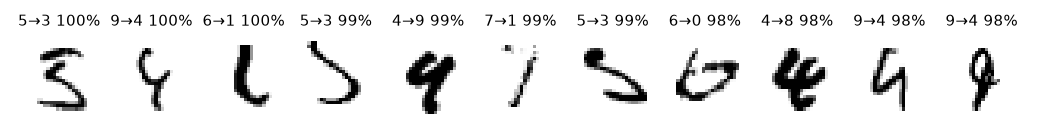

In [8]:
most_confident = wrong[np.argsort(confidence[wrong])[::-1][:11]]

show(most_confident)

## Look at any one image

Change `INDEX` and run this cell again. A value from 0 to 65 picks one of the mistakes, in the same order as the grid of 66. The bars show all ten outputs, with the true digit in blue and the predicted digit in orange.

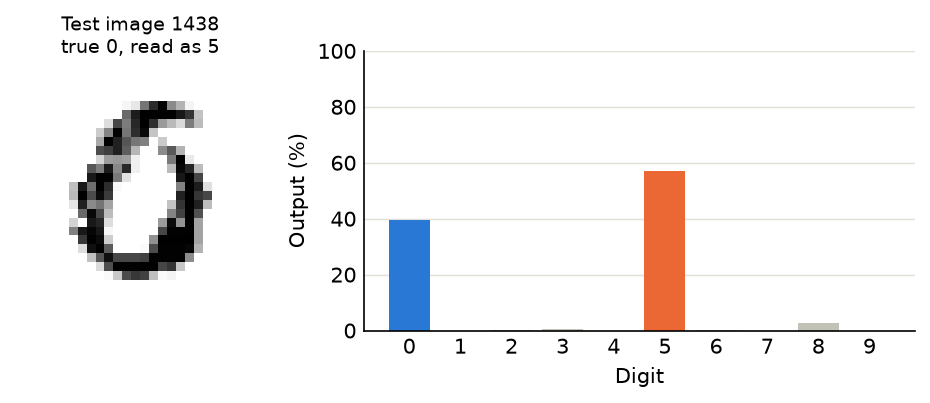

In [9]:
INDEX = 0

index = wrong[order][INDEX]
true, predicted = testing_labels[index], predicted_labels[index]

colours = ['#c3c2b7']*10
colours[true], colours[predicted] = BLUE, ORANGE

fig, (left, right_panel) = plt.subplots(1, 2, figsize=(6.3, 2.6), gridspec_kw={'width_ratios': [1, 2.2]})

left.imshow(testing_inputs[index], cmap='gray_r', vmin=0, vmax=255)
left.axis('off')
left.set_title("Test image {}\ntrue {}, read as {}".format(index, true, predicted), fontsize=9)

right_panel.bar(range(10), responses[index]*100, color=colours)
right_panel.set_xticks(range(10))
right_panel.set_ylim(0, 100)
right_panel.grid(True, axis='y', color='#e1e0d9', linewidth=0.7)
right_panel.set_axisbelow(True)
right_panel.spines[['top', 'right']].set_visible(False)
right_panel.tick_params(length=0)
right_panel.set_xlabel('Digit')
right_panel.set_ylabel('Output (%)')

fig.tight_layout()
plt.show()